# Sketch ↔ Photo Matching with DINOv3 (contrastive learning)
**ELEC 475 Lab 5: student notebook.** The handout explains the lab; this notebook is where you do it.

Someone looks at a photo, then draws it from memory. Your model gets the **sketch** and must find the **exact photo**
it was drawn from, out of 1,250 test photos. The Sketchy paper's best model got this right 37.1% of the time, and
people about 54%. Can you beat them?

```
 photo   ─► DINOv3 (frozen) ──────────────────────────────┐
 sketch  ─► DINOv3 copy (trained) ─► projection head ─────┴─► InfoNCE loss
```

**How to read this notebook:** you write code in the sections marked **Task**; the other code cells are given.
Given code is hidden: click **Show code** to read it. After Tasks 1, 2, 3 and 6, a **check** cell tests your code.

| Task | Section | What you write |
|---|---|---|
| 1 | 10 | the projection head |
| 2 | 11 | the InfoNCE loss |
| 3 | 12 | the training loop (3a–3d) |
| 4 | 13 | loss curves |
| 5 | 15 | retrieval examples |
| 6 | 16 | classify sketches from a list of classes |
| 7 | after 17 | two modifications, alone and together |

**Start here:** set up DINOv3 access (handout §2.1, or open the box below), choose **Runtime → Change runtime type →
T4 GPU**, set `QUICK_RUN=True` in section 1, then **Runtime → Run all**.

<details><summary><b>DINOv3 access, step by step</b> (click to open)</summary>

1. Make a free account at https://huggingface.co.
2. Open https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m and **request access**. Approval can take a
   while, so do this early.
3. In Hugging Face: *Settings → Access Tokens → Create new token* (type **Read**). Copy it.
4. In Colab: click the **key icon** (Secrets) on the left → *Add new secret* → name `HF_TOKEN`, paste the token, and
   switch on *Notebook access*.

No access yet? You can still work: the notebook then uses **DINOv2-small** and tells you so.

</details>

<details><summary><b>Words used in this lab</b> (click to open)</summary>

| Word | Meaning |
|---|---|
| feature / embedding | a list of numbers that describes an image; similar images get similar lists |
| frozen | the weights are not changed by training |
| fine-tune | keep training a model that was already trained, so it adapts to a new task |
| projection head | a small network that maps sketch features into the photo feature space |
| cosine similarity | how closely two vectors point the same way (1 = same direction, 0 = unrelated) |
| Recall@K (R@K) | the % of queries with a right answer in the top K results |
| instance / category | the exact photo the sketch was drawn from / any photo of the same class |

</details>

# Part A: Setup (sections 1–4)

## 1. Settings
The only given cell you edit. Every setting for a run is in `CFG`.
* **First time:** `QUICK_RUN=True` (a small subset, a few minutes). Then `False` for real runs.
* **A modification:** change a setting (or your code), set a new `RUN_TAG`, and **Run all**. Each run gets its own
  folder.
* **Colab disconnects** wipe `/content`. `SAVE_TO_DRIVE=True` keeps your runs in Google Drive.
* **Right after your base run**, download this notebook (*File → Download → .ipynb*) as `base_run.ipynb`.

In [1]:
CFG = dict(
    # ---- model ----
    BACKBONE='auto',     # 'auto' = DINOv3 if your token works, else DINOv2-small
    TRAIN_BLOCKS=12,     # last DINO blocks to train (0 = only the head)
    HIDDEN_DIM=1024,     # hidden size of the projection head
    AUG='strong',          # 'none' or 'strong' (sketch augmentation, section 9)

    # ---- training ----
    EPOCHS=None,         # None = 20 (or 60 when TRAIN_BLOCKS = 0)
    BATCH_SIZE=128,      # pairs per step (more = more negatives)
    LR_HEAD=1e-3,        # learning rate: head and temperature
    LR_BACKBONE=2e-5,    # learning rate: sketch-side DINO
    WEIGHT_DECAY=0.05,   # AdamW weight decay
    WARMUP_STEPS=100,    # warm-up steps (at most 10% of all steps)
    TEMP_INIT=0.07,      # starting InfoNCE temperature (it is learned)
    LOSS='infonce',      # Task 7 B: 'infonce' or 'infonce_cls' (+ classification loss)
    CLS_WEIGHT=0.5,      # Task 7 B: weight of the classification loss
    SEED=0,              # random seed
    RUN_TAG='aug',          # short name for a modification, e.g. 'triplet'
    QUICK_RUN=False,     # True = tiny subset, to test your code fast

    # ---- saving and data ----
    SAVE_TO_DRIVE=False,                       # True = keep your runs in Google Drive
    DRIVE_DIR='/content/drive/MyDrive/sketch_lab',
    LOCAL_ZIP='',        # only if the download fails: path to sketchy_student.zip
)

# ---- running on a local machine instead of Colab (ignored in Colab) ----
import sys
if 'google.colab' not in sys.modules:
    CFG.update(DATA_DIR='data', CACHE_DIR='data/cache', RUNS_DIR='runs',
               NUM_WORKERS=0)   # macOS cannot send notebook-defined Datasets to worker processes


## 2. Setup
Checks the GPU and the `transformers` version, finds your Hugging Face token, picks the model, and makes this run's
folder.

In [2]:
# @title 2. Setup (given) { display-mode: "form" }
import os, sys, csv, json, math, time, random, subprocess, zipfile
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # local patch: Apple GPU
from pathlib import Path
from importlib.metadata import version as pkg_version

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from packaging.version import Version

# Settings students never change (kept here so the Settings cell stays short)
# Google Drive id of sketchy_student.zip
CFG.setdefault('STUDENT_ZIP_ID', '1VzzfJdszuVJTyxpefE93C9sP8soIe-q1')
CFG.setdefault('DATA_DIR', '/content/data')
CFG.setdefault('CACHE_DIR', '/content/cache')   # saved DINO features
CFG.setdefault('RUNS_DIR', '')                  # '' = automatic
CFG.setdefault('NUM_WORKERS', 2)                # free Colab has 2 CPU cores
CFG.setdefault('QUICK_CLASSES', 20)             # classes used when QUICK_RUN = True
# Optional override, used for local testing
CFG.update(json.loads(os.environ.get('SKETCH_LAB_CFG', '{}')))
IN_COLAB = 'google.colab' in sys.modules

# DINOv3 needs transformers 4.56 or newer
if Version(pkg_version('transformers')) < Version('4.56'):
    if 'transformers' in sys.modules:
        raise RuntimeError('transformers is too old and already loaded. '
                           'Run: !pip install -U "transformers>=4.56", '
                           'then Runtime -> Restart session, and Run all again.')
    print('Upgrading transformers (DINOv3 needs >= 4.56)...')
    pip_command = [sys.executable, '-m', 'pip', 'install', '-q', '-U', 'transformers>=4.56']
    subprocess.run(pip_command, check=True)
print('transformers', pkg_version('transformers'))

# Hugging Face token: DINOv3 needs one, DINOv2 does not
HF_TOKEN = os.environ.get('HF_TOKEN')
if not HF_TOKEN and not IN_COLAB:   # local patch: the token saved by `hf auth login`
    from huggingface_hub import get_token
    HF_TOKEN = get_token()
if IN_COLAB and not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('HF_TOKEN')
    except Exception as e:
        print('Could not read the HF_TOKEN secret:', type(e).__name__)

DINOV3 = 'facebook/dinov3-vits16-pretrain-lvd1689m'
DINOV2 = 'facebook/dinov2-small'


def dinov3_problem():
    """None if DINOv3 loads with the token, else the reason."""
    if not HF_TOKEN:
        return 'no HF_TOKEN found'
    try:
        from transformers import AutoConfig
        AutoConfig.from_pretrained(DINOV3, token=HF_TOKEN)   # downloads only a small config file
        return None
    except Exception as e:
        reason = type(e).__name__
        return (f'your HF_TOKEN cannot load DINOv3 yet '
                f'(access not approved, or a wrong token: {reason})')


if CFG['BACKBONE'] == 'auto':
    problem = dinov3_problem()
    if problem is None:
        CFG['BACKBONE'] = DINOV3
    else:
        CFG['BACKBONE'] = DINOV2
        print('=' * 78)
        print(f'NOTE: {problem},')
        print('so this run uses DINOv2-small instead,')
        print('which is fine while you wait for DINOv3 access.')
        print('Say which model you used in your report.')
        print('=' * 78)
if 'dinov3' in CFG['BACKBONE'].lower() and not HF_TOKEN:
    raise RuntimeError(
        'DINOv3 needs a Hugging Face token.\n'
        f"  1) Request access at https://huggingface.co/{CFG['BACKBONE']}\n"
        '  2) Create a Read token: huggingface.co -> Settings -> Access Tokens\n'
        '  3) Colab key icon (Secrets) -> add HF_TOKEN, switch on "Notebook access"\n'
        "Or, while you wait for access: set BACKBONE = 'auto' in the Settings cell (section 1).")
print('Model:', CFG['BACKBONE'])

# Google Drive: only needed if you save there or your zip is there
if IN_COLAB and (CFG['SAVE_TO_DRIVE'] or CFG['LOCAL_ZIP'].startswith('/content/drive')):
    from google.colab import drive
    drive.mount('/content/drive')

# Local patch: also use an Apple-silicon GPU (MPS); mixed precision stays CUDA-only (fp32 on MPS)
if torch.cuda.is_available():
    DEVICE = 'cuda'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'
USE_AMP = DEVICE == 'cuda'
if DEVICE == 'cuda':
    HARDWARE = torch.cuda.get_device_name(0)
elif DEVICE == 'mps':
    chip = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'],
                          capture_output=True, text=True).stdout.strip()
    HARDWARE = f'{chip} GPU (MPS)'
else:
    HARDWARE = 'CPU'
FINETUNE = CFG['TRAIN_BLOCKS'] > 0   # False = the sketch-side DINO is frozen too
QUICK = CFG['QUICK_RUN']
print(f'Device: {DEVICE} ({HARDWARE})   torch {torch.__version__}')
if DEVICE == 'cpu':
    print('WARNING: no GPU. In Colab: Runtime -> Change runtime type -> T4 GPU.')
if not FINETUNE and CFG['AUG'] != 'none':
    print('WARNING: AUG is ignored when TRAIN_BLOCKS = 0 (the sketch features are computed once).')


def amp():
    """Mixed precision: `with amp():` (GPU only)."""
    return torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP)


def set_seed(seed):
    """Seed Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if torch.backends.mps.is_available():   # local patch
        torch.mps.manual_seed(seed)


set_seed(CFG['SEED'])

# This run's folder, named after its main settings
SLUG = CFG['BACKBONE'].split('/')[-1]   # short model name
RUN_NAME = f"{SLUG}_blocks{CFG['TRAIN_BLOCKS']}_aug-{CFG['AUG']}"
if CFG['SEED']:
    RUN_NAME += f"_seed{CFG['SEED']}"
if CFG['RUN_TAG']:
    RUN_NAME += f"_{CFG['RUN_TAG']}"
if QUICK:
    RUN_NAME += '_quick'

if CFG['RUNS_DIR']:
    RUNS = Path(CFG['RUNS_DIR'])
elif CFG['SAVE_TO_DRIVE']:
    RUNS = Path(CFG['DRIVE_DIR']) / 'runs'
else:
    RUNS = Path('/content/runs')
RUN_DIR = RUNS / RUN_NAME
CACHE = Path(CFG['CACHE_DIR'])
RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
print('This run is saved in:', RUN_DIR)

transformers 5.24.0


Model: facebook/dinov3-vits16-pretrain-lvd1689m
Device: mps (Apple M4 Pro GPU (MPS))   torch 2.14.0
This run is saved in: runs/dinov3-vits16-pretrain-lvd1689m_blocks12_aug-strong_aug


## 3. Get the data
Downloads the dataset (about 1.1 GB) straight into Colab and unzips it (about 2 minutes). Skipped if it is already
there.

In [3]:
# @title 3. Get the data (given) { display-mode: "form" }
DATA_ROOT = Path(CFG['DATA_DIR']) / 'sketchy_student'
DOWNLOAD_HELP = (
    'The download failed. Google sometimes blocks a shared file after many downloads. Try this:\n'
    f"  1) Open https://drive.google.com/file/d/{CFG['STUDENT_ZIP_ID']}/view in your browser\n"
    '  2) Click "Add shortcut to Drive" (or make a copy in your Drive)\n'
    "  3) Set LOCAL_ZIP = '/content/drive/MyDrive/sketchy_student.zip' in the Settings cell "
    "(section 1) and Run all again.")


def download_zip(zip_path):
    """Download the dataset zip from Google Drive."""
    import gdown
    try:
        ok = gdown.download(id=CFG['STUDENT_ZIP_ID'], output=str(zip_path), quiet=False)
    except Exception as e:
        raise RuntimeError(DOWNLOAD_HELP) from e
    if not ok or not zip_path.exists():
        raise RuntimeError(DOWNLOAD_HELP)


def get_data():
    """Unzip the dataset into DATA_ROOT (once)."""
    if (DATA_ROOT / 'splits.csv').exists():
        print('Data ready in', DATA_ROOT)
        return
    Path(CFG['DATA_DIR']).mkdir(parents=True, exist_ok=True)
    if CFG['LOCAL_ZIP']:
        zip_path = Path(CFG['LOCAL_ZIP'])
        if not zip_path.exists():
            raise FileNotFoundError(f'LOCAL_ZIP not found: {zip_path}')
    else:
        zip_path = Path(CFG['DATA_DIR']) / 'sketchy_student.zip'
        if not zip_path.exists():
            download_zip(zip_path)
    t0 = time.time()
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(CFG['DATA_DIR'])
    if not CFG['LOCAL_ZIP']:
        zip_path.unlink()   # free the disk space
    print(f'Unzipped in {time.time() - t0:.0f}s')


get_data()

Data ready in data/sketchy_student


## 4. Load the fixed split
Every class has 10 test photos, 5 validation photos, and the rest are for training. A sketch is always in the same
split as its photo. In each split, the **photos** are the gallery we search and the **sketches** are the queries.

<details><summary><b>Names you will use</b> (click to open)</summary>

The three splits are `train_split`, `val_split` and `test_split`.

| Name | What it is |
|---|---|
| `split.photo_paths[i]`, `split.photo_cls[i]` | path and class number of photo `i` |
| `split.photo_feats[i]` | frozen DINO feature of photo `i` (added in section 6) |
| `split.sketch_paths[j]`, `split.sketch_cls[j]` | path and class number of sketch `j` |
| `split.sketch_pidx[j]` | index of the photo that sketch `j` was drawn from |
| `split.sketches_of[i]` | list of the sketches drawn from photo `i` |
| `CLASS_NAMES[c]` | readable name of class number `c` |

</details>

In [4]:
# @title 4. Load the split (given) { display-mode: "form" }
with open(DATA_ROOT / 'splits.csv') as f:
    rows = list(csv.DictReader(f))
CLASSES = sorted({r['cls'] for r in rows})
if QUICK:
    CLASSES = CLASSES[:CFG['QUICK_CLASSES']]
    keep = set(CLASSES)
    rows = [r for r in rows if r['cls'] in keep]
CLASS_NAMES = [c.replace('_', ' ').replace('-', ' ') for c in CLASSES]   # readable names
cls2idx = {c: i for i, c in enumerate(CLASSES)}                          # class name -> number


class Split:
    """One split: train, val or test (names in the markdown above)."""

    def __init__(self, name, max_sketches=None):
        self.name = name

        # Photos, sorted by id
        photo_rows = [r for r in rows if r['split'] == name and r['kind'] == 'photo']
        photo_rows.sort(key=lambda r: r['photo_id'])
        photo_index = {r['photo_id']: i for i, r in enumerate(photo_rows)}
        self.photo_paths = [r['path'] for r in photo_rows]
        self.photo_cls = torch.tensor([cls2idx[r['cls']] for r in photo_rows])

        # Sketches, in a fixed mixed-up order (QUICK_RUN keeps only the first max_sketches)
        sketch_rows = [r for r in rows if r['split'] == name and r['kind'] == 'sketch']
        random.Random(CFG['SEED']).shuffle(sketch_rows)
        if max_sketches:
            sketch_rows = sketch_rows[:max_sketches]
        self.sketch_paths = [r['path'] for r in sketch_rows]
        self.sketch_pidx = torch.tensor([photo_index[r['photo_id']] for r in sketch_rows])
        self.sketch_cls = torch.tensor([cls2idx[r['cls']] for r in sketch_rows])

        # Links between them
        self.sketches_of = [[] for _ in photo_rows]
        for j, i in enumerate(self.sketch_pidx.tolist()):
            self.sketches_of[i].append(j)
        self.photos_with_sketches = [i for i, s in enumerate(self.sketches_of) if s]

    def __repr__(self):
        n_photos = len(self.photo_paths)
        n_sketches = len(self.sketch_paths)
        return f'{self.name:5s}: {n_photos:6,d} photos  {n_sketches:6,d} sketches'


if QUICK:
    train_split = Split('train', max_sketches=2000)
    val_split = Split('val', max_sketches=400)
    test_split = Split('test', max_sketches=800)
else:
    train_split = Split('train')
    val_split = Split('val')
    test_split = Split('test')
SPLITS = (train_split, val_split, test_split)
print(f'{len(CLASSES)} classes')
for s in SPLITS:
    print(' ', s)

125 classes
  train: 10,625 photos  64,105 sketches
  val  :    625 photos   3,828 sketches
  test :  1,250 photos   7,548 sketches


# Part B: Data and baseline (sections 5–8)

## 5. Look at the data
6 training sketches (top) and the photos they were drawn from (bottom). This cell also defines `load_rgb(path)`,
which you will use in Tasks 5 and 6.

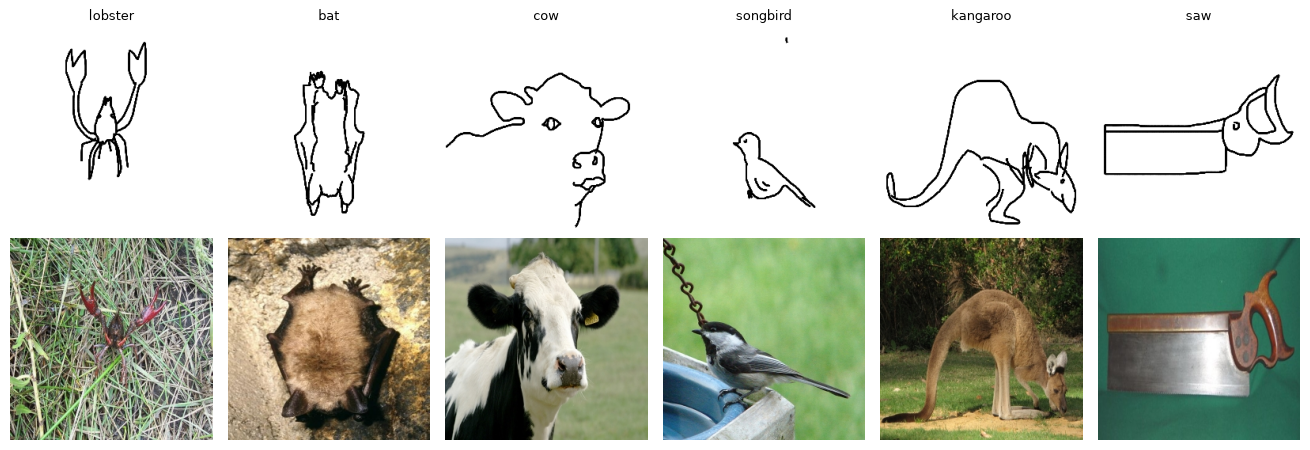

In [5]:
# @title 5. Look at the data (given) { display-mode: "form" }
def load_rgb(rel_path):
    """Open an image as RGB, on a white background."""
    im = Image.open(DATA_ROOT / rel_path)
    has_alpha = im.mode in ('RGBA', 'LA') or (im.mode == 'P' and 'transparency' in im.info)
    if has_alpha:
        im = im.convert('RGBA')
        white = Image.new('RGBA', im.size, (255, 255, 255, 255))
        im = Image.alpha_composite(white, im)
    return im.convert('RGB')


def show_pairs(split, n=6, seed=1):
    """Plot n sketches above their photos; save data_pairs.png."""
    idx = random.Random(seed).sample(range(len(split.sketch_paths)), n)
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 4.6))
    for col, j in enumerate(idx):
        axes[0, col].imshow(load_rgb(split.sketch_paths[j]))
        axes[0, col].set_title(CLASS_NAMES[split.sketch_cls[j]], fontsize=9)
        axes[1, col].imshow(load_rgb(split.photo_paths[split.sketch_pidx[j]]))
    for ax in axes.flat:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'data_pairs.png', dpi=110)
    plt.show()


show_pairs(train_split)

## 6. The frozen photo side: DINOv3 features (computed once)
Each image's feature is **[CLS token, average of the patch vectors]**: 2 × 384 = 768 numbers (`FEAT_DIM`). The photo
side never changes, so every photo's feature is computed once and saved (a few minutes on a T4). The test sketches
are done too, for the "no training" baseline in section 8. If you **Run all** again in the same session, the saved
features are loaded instead.

In [6]:
# @title 6. Compute the frozen photo features (given) { display-mode: "form" }
from transformers import AutoModel

IMNET_MEAN = (0.485, 0.456, 0.406)   # the colour normalisation DINO expects
IMNET_STD = (0.229, 0.224, 0.225)
IMG_SIZE = 224
base_tf = T.Compose([             # the standard image transform (no augmentation)
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMNET_MEAN, IMNET_STD),
])


def load_backbone():
    """Load CFG['BACKBONE'], frozen, on DEVICE."""
    try:
        model = AutoModel.from_pretrained(CFG['BACKBONE'], token=HF_TOKEN)
    except Exception as e:
        raise RuntimeError(
            f"Could not load {CFG['BACKBONE']}.\n"
            'If this is DINOv3: check that your access was approved at '
            f"https://huggingface.co/{CFG['BACKBONE']} and that HF_TOKEN is set.\n"
            "Fallback: set BACKBONE = 'facebook/dinov2-small' in the Settings cell (section 1).\n"
            f'Original error: {e}') from e
    model = model.to(DEVICE).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


backbone = load_backbone()   # the frozen photo-side DINO
# DINOv3 has 4 "register" tokens after the CLS token (DINOv2 has none); the feature skips them
N_REG = getattr(backbone.config, 'num_register_tokens', 0) or 0
FEAT_DIM = 2 * backbone.config.hidden_size   # [CLS, patch mean]
print(f"{CFG['BACKBONE']}: hidden size {backbone.config.hidden_size}, "
      f"{N_REG} register tokens -> feature size {FEAT_DIM}")


def dino_features(model, x):
    """Images [B, 3, 224, 224] -> features [B, FEAT_DIM]."""
    tokens = model(pixel_values=x).last_hidden_state   # CLS, registers, patches
    cls_token = tokens[:, 0]
    patch_mean = tokens[:, 1 + N_REG:].mean(1)
    return torch.cat([cls_token, patch_mean], dim=-1)


class ImageList(Dataset):
    """Dataset: image paths -> tensors (+ labels if given)."""

    def __init__(self, paths, tf, labels=None):
        self.paths = paths
        self.tf = tf
        self.labels = labels

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        x = self.tf(load_rgb(self.paths[i]))
        if self.labels is None:
            return x
        return x, self.labels[i]


@torch.no_grad()
def extract_features(paths, bs=256):
    """Frozen DINO features of these images (half precision, CPU)."""
    loader = DataLoader(ImageList(paths, base_tf), batch_size=bs, num_workers=CFG['NUM_WORKERS'])
    out = []
    for i, x in enumerate(loader):
        with amp():
            feats = dino_features(backbone, x.to(DEVICE))
        out.append(feats.half().cpu())
        if i % 50 == 0:
            print(f'  {min((i + 1) * bs, len(paths)):,}/{len(paths):,}')
    return torch.cat(out)


# Saved features are needed for the photos of every split and the test sketches (for the baseline).
# With TRAIN_BLOCKS = 0 the sketch side is frozen too, so training also uses saved sketch features.
if FINETUNE:
    SKETCH_FEAT_SPLITS = (test_split,)
else:
    SKETCH_FEAT_SPLITS = SPLITS

# One cache file per backbone; only the images that are not in it yet are computed
feat_file = CACHE / f'feats_{SLUG}.pt'
if feat_file.exists():
    cache = torch.load(feat_file)
else:
    cache = {'paths': [], 'feats': torch.zeros(0, FEAT_DIM, dtype=torch.half)}
row_of = {p: i for i, p in enumerate(cache['paths'])}

needed = set()
for s in SPLITS:
    needed.update(s.photo_paths)
for s in SKETCH_FEAT_SPLITS:
    needed.update(s.sketch_paths)
missing = sorted(p for p in needed if p not in row_of)

if missing:
    t0 = time.time()
    print(f'Computing DINO features for {len(missing):,} images...')
    new_feats = extract_features(missing)
    cache = {'paths': cache['paths'] + missing, 'feats': torch.cat([cache['feats'], new_feats])}
    torch.save(cache, feat_file)
    row_of = {p: i for i, p in enumerate(cache['paths'])}
    print(f'Done in {(time.time() - t0) / 60:.1f} min')
else:
    print('Loaded saved features from', feat_file)


def saved_features(paths):
    """Saved features of these images, on DEVICE."""
    rows_needed = [row_of[p] for p in paths]
    return cache['feats'][rows_needed].to(DEVICE)


for s in SPLITS:
    s.photo_feats = saved_features(s.photo_paths)
for s in SKETCH_FEAT_SPLITS:
    s.sketch_feats = saved_features(s.sketch_paths)

W1122 23:02:10.130000 60089 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

facebook/dinov3-vits16-pretrain-lvd1689m: hidden size 384, 4 register tokens -> feature size 768
Loaded saved features from data/cache/feats_dinov3-vits16-pretrain-lvd1689m.pt


## 7. How we score (please don't change)
Each test sketch is compared with every test photo (cosine similarity), and the photos are sorted from most to least
alike. **Recall@K (R@K)** is the % of sketches with a correct photo in the top K. The main score is
**sketch → exact photo R@1**, the Sketchy paper's score.

In Task 3 you call `evaluate(sketch_embeddings, photo_embeddings, split)`. It returns
`{'s2p_inst': {1: R@1, 5: R@5, 10: R@10}, 's2p_cat': ..., 'p2s_inst': ..., 'p2s_cat': ...}`, in %.

<details><summary><b>The four scores</b> (click to open)</summary>

| Key | Query → what we search | Correct if... |
|---|---|---|
| `s2p_inst` (main score) | sketch → test photos | the **exact photo** is in the top K |
| `s2p_cat` | sketch → test photos | a photo of the **same class** is in the top K |
| `p2s_inst`, `p2s_cat` | photo → test sketches | the same rules, the other way round |

</details>

In [7]:
# @title 7. Scoring code (given: please don't change) { display-mode: "form" }
@torch.no_grad()
def recall_at_k(sim, q_lab, g_lab, ks=(1, 5, 10)):
    """{K: % of queries whose top K holds an item with the same label}."""
    k_max = min(max(ks), sim.shape[1])
    top = sim.topk(k_max, dim=1).indices
    hits = g_lab[top] == q_lab[:, None]
    result = {}
    for k in ks:
        result[k] = hits[:, :k].any(1).float().mean().item() * 100
    return result


@torch.no_grad()
def evaluate(sk_emb, ph_emb, split):
    """R@1/5/10 in both directions for one split (inputs: embed_split())."""
    sim = sk_emb.float().cpu() @ ph_emb.float().cpu().T   # cosine similarities
    photo_idx = torch.arange(len(split.photo_paths))

    # Photo queries: only the photos that have sketches
    has_sketch = torch.zeros(len(photo_idx), dtype=torch.bool)
    has_sketch[split.sketch_pidx] = True
    sim_p2s = sim.T[has_sketch]

    return {
        's2p_cat': recall_at_k(sim, split.sketch_cls, split.photo_cls),
        's2p_inst': recall_at_k(sim, split.sketch_pidx, photo_idx),
        'p2s_cat': recall_at_k(sim_p2s, split.photo_cls[has_sketch], split.sketch_cls),
        'p2s_inst': recall_at_k(sim_p2s, photo_idx[has_sketch], split.sketch_pidx),
    }


def print_results(results):
    """Print R@1/5/10 tables side by side. results: {name: scores}."""
    score_rows = [('Sketch->Photo  instance', 's2p_inst'), ('Sketch->Photo  category', 's2p_cat'),
                  ('Photo->Sketch  instance', 'p2s_inst'), ('Photo->Sketch  category', 'p2s_cat')]
    names = list(results)
    header = f"{'':25s}"
    sub_header = f"{'':25s}"
    for name in names:
        header += f'{name[:30]:>32s}'
        sub_header += f"{'R@1    R@5   R@10':>32s}"
    print(header)
    print(sub_header)
    for label, key in score_rows:
        line = f'{label:25s}'
        for name in names:
            r = results[name][key]
            line += f'{r[1]:16.1f}{r[5]:7.1f}{r[10]:7.1f}  '
        print(line)


# Sketch -> exact photo R@1 in published work (Sketchy test protocol: 1,250 test photos)
PUBLISHED_R1 = {
    'Sketchy paper, best model (Sangkloy et al., 2016)': 37.1,   # GoogLeNet, triplet + class loss
    'Humans (Sangkloy et al., 2016)': 54,                        # "54% of the time", 772 trials
    'Seddati et al., 2022 (fine-tuned ViT)': 62.25,
}

## 8. Baseline: raw DINOv3 features, no training
Raw sketch features compared straight with raw photo features. **This is the score to beat.** Expect it to be low,
especially for the exact photo: DINO was never taught that a drawing and a photo can show the same thing.

**For your report:** copy this table (it is also saved in your runs folder).

In [8]:
# @title 8. Baseline (given) { display-mode: "form" }
raw_sketches = F.normalize(test_split.sketch_feats.float(), dim=-1)
raw_photos = F.normalize(test_split.photo_feats.float(), dim=-1)
baseline = evaluate(raw_sketches, raw_photos, test_split)
quick_suffix = '_quick' if QUICK else ''
with open(RUNS / f'baseline_{SLUG}{quick_suffix}.json', 'w') as f:
    json.dump(dict(backbone=CFG['BACKBONE'], test=baseline), f, indent=1)
print_results({f'{SLUG} raw (no training)': baseline})

                           dinov3-vits16-pretrain-lvd1689
                                        R@1    R@5   R@10
Sketch->Photo  instance              14.8   37.4   48.6  
Sketch->Photo  category              39.5   65.8   76.2  
Photo->Sketch  instance              36.8   67.8   78.3  
Photo->Sketch  category              78.6   89.9   92.2  


# Part C: Build the model (sections 9–11)

## 9. Training batches and the sketch model
Ready-made helpers for sections 12–16. A batch is `(x, pidx)`: `x` holds the sketches, and `pidx[k]` is the index of
the photo that sketch `k` was drawn from, so the matching photo features are `train_split.photo_feats[pidx]`.

<details><summary><b>The helpers</b> (click to open)</summary>

| Helper | What it gives you |
|---|---|
| `train_batches()` | one epoch of batches: one random sketch per training photo, shuffled (no photo twice in a batch) |
| `val_loss_batches()` | batches with one fixed sketch per validation photo, for the validation loss |
| `eval_batches(split)` | batches with all the sketches of a split, in order, for scoring |
| `n_train_batches()` | the number of training steps in one epoch |
| `embed_split(sketch_model, split)` | the normalised embeddings of all the sketches and photos of a split |
| `SketchModel` | the sketch side (DINO copy + your head): `sketch_model(x)` gives sketch embeddings |

With `TRAIN_BLOCKS = 0`, `x` holds saved DINO features instead of images; your code stays the same.

</details>

**Optional:** the small cell below is only for the sketch-augmentation modification (`AUG='strong'`).
With the default `AUG='none'`, run it unchanged.

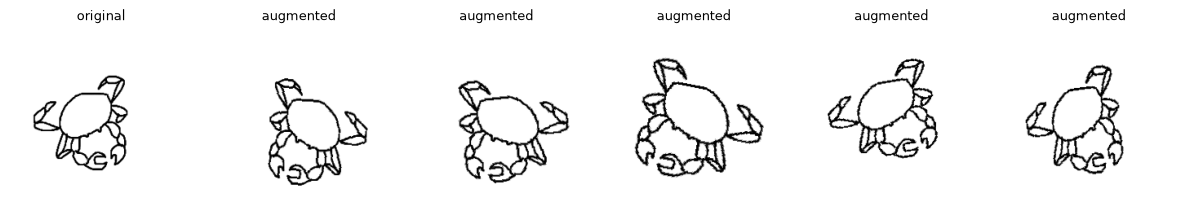

In [9]:
def sketch_transform(train):
    """Sketch transform: augmented if training with AUG='strong'."""
    if train and CFG['AUG'] == 'strong':
        # Task 7 A: geometric changes only, so the strokes stay clean black lines on white.
        # People draw from memory, so a sketch is often shifted, scaled, tilted or mirrored
        # relative to its photo; these transforms teach the model to ignore exactly that.
        white = (255, 255, 255)
        aug = [
            T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.85, 1.15)),
            T.RandomHorizontalFlip(),
            T.RandomAffine(degrees=15, translate=(0.08, 0.08), scale=(0.9, 1.1), fill=white),
        ]
        return T.Compose(aug + [T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])
    return base_tf


if CFG['AUG'] == 'strong':   # show what the augmentation does (figure for the report)
    _tf = sketch_transform(True)
    _sk = train_split.sketch_paths[0]
    fig, axes = plt.subplots(1, 6, figsize=(12, 2.3))
    axes[0].imshow(load_rgb(_sk).resize((IMG_SIZE, IMG_SIZE)))
    axes[0].set_title('original', fontsize=9)
    for ax in axes[1:]:
        x = _tf(load_rgb(_sk))
        x = x * torch.tensor(IMNET_STD)[:, None, None] + torch.tensor(IMNET_MEAN)[:, None, None]
        ax.imshow(x.permute(1, 2, 0).clamp(0, 1))
        ax.set_title('augmented', fontsize=9)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'aug_examples.png', dpi=120)
    plt.show()


In [10]:
# @title 9. Batch helpers and the sketch model (given) { display-mode: "form" }
class OneSketchPerPhoto(Dataset):
    """Item k = (a random sketch of a photo, that photo's index)."""

    def __init__(self, split, tf):
        self.split = split
        self.tf = tf
        self.photos = split.photos_with_sketches

    def __len__(self):
        return len(self.photos)

    def __getitem__(self, k):
        i = self.photos[k]
        j = random.choice(self.split.sketches_of[i])   # a new random sketch every epoch
        return self.tf(load_rgb(self.split.sketch_paths[j])), i


def first_sketch_per_photo(split):
    """The first sketch of each photo: (sketch indices, photo indices)."""
    photos = split.photos_with_sketches
    sketches = [split.sketches_of[i][0] for i in photos]
    return sketches, photos


def make_loader(ds, train):
    """DataLoader; train=True shuffles and drops the last partial batch."""
    nw = CFG['NUM_WORKERS']
    return DataLoader(ds, batch_size=CFG['BATCH_SIZE'], shuffle=train, drop_last=train,
                      num_workers=nw, pin_memory=(DEVICE == 'cuda'), persistent_workers=(nw > 0),
                      generator=torch.Generator().manual_seed(CFG['SEED']))


# Image loaders: only needed when the sketch-side DINO trains (otherwise we use saved features)
if FINETUNE:
    loaders = {'train': make_loader(OneSketchPerPhoto(train_split, sketch_transform(True)), True)}
    for s in (val_split, test_split):
        loaders[s.name] = make_loader(ImageList(s.sketch_paths, base_tf, s.sketch_pidx), False)
    j, i = first_sketch_per_photo(val_split)
    val_paths = [val_split.sketch_paths[k] for k in j]
    loaders['val_loss'] = make_loader(ImageList(val_paths, base_tf, i), False)


def train_batches():
    """One epoch of (sketches, photo indices): a random sketch per photo."""
    if FINETUNE:
        for x, pidx in loaders['train']:
            yield x.to(DEVICE, non_blocking=True), pidx.to(DEVICE)
    else:
        photos = torch.tensor(train_split.photos_with_sketches)
        pick = torch.tensor([random.choice(train_split.sketches_of[i]) for i in photos.tolist()])
        perm = torch.randperm(len(photos))
        bs = CFG['BATCH_SIZE']
        for b in range(0, len(perm) - bs + 1, bs):   # drops the last incomplete batch
            idx = perm[b:b + bs]
            yield train_split.sketch_feats[pick[idx].to(DEVICE)], photos[idx].to(DEVICE)


def val_loss_batches():
    """Like train_batches(), with a fixed sketch per validation photo."""
    if FINETUNE:
        for x, pidx in loaders['val_loss']:
            yield x.to(DEVICE, non_blocking=True), pidx.to(DEVICE)
    else:
        j, i = first_sketch_per_photo(val_split)
        j = torch.tensor(j)
        i = torch.tensor(i)
        for b in range(0, len(j), 1024):
            yield val_split.sketch_feats[j[b:b + 1024].to(DEVICE)], i[b:b + 1024].to(DEVICE)


def eval_batches(split):
    """All the sketches of a split, in order (for scoring)."""
    if FINETUNE:
        for x, pidx in loaders[split.name]:
            yield x.to(DEVICE, non_blocking=True), pidx.to(DEVICE)
    else:
        for b in range(0, len(split.sketch_paths), 1024):
            yield split.sketch_feats[b:b + 1024], split.sketch_pidx[b:b + 1024].to(DEVICE)


def n_train_batches():
    """Training steps per epoch."""
    return len(train_split.photos_with_sketches) // CFG['BATCH_SIZE']


class SketchModel(nn.Module):
    """The sketch side: DINO copy + your head."""

    def __init__(self, head, backbone=None):
        super().__init__()
        self.head = head
        self.backbone = backbone

    def forward(self, x):
        """A batch -> [B, FEAT_DIM] embeddings (not normalised)."""
        if self.backbone is not None:
            x = dino_features(self.backbone, x)
        return self.head(x.float())


def make_finetune_backbone(n_last):
    """A DINO copy whose last n_last blocks train."""
    model = load_backbone()
    blocks = None
    for m in model.modules():   # find the list of transformer blocks
        if isinstance(m, nn.ModuleList) and len(m) == model.config.num_hidden_layers:
            blocks = m
            break
    for block in blocks[-n_last:]:
        for p in block.parameters():
            p.requires_grad_(True)
    for child in model.children():   # the final LayerNorm
        if isinstance(child, nn.LayerNorm):
            for p in child.parameters():
                p.requires_grad_(True)
    model.train()
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'Sketch-side DINO: training the last {min(n_last, len(blocks))} of {len(blocks)} blocks '
          f'({n_train / 1e6:.1f}M parameters)')
    return model


@torch.no_grad()
def embed_split(sketch_model, split):
    """Normalised (sketch, photo) embeddings of a split, for evaluate()."""
    sketch_model.eval()
    sketch_embs = []
    for x, _ in eval_batches(split):
        with amp():
            s = sketch_model(x)
        sketch_embs.append(F.normalize(s.float(), dim=-1).cpu())
    photo_embs = F.normalize(split.photo_feats.float(), dim=-1).cpu()
    return torch.cat(sketch_embs), photo_embs


print('Helpers ready.', f'{n_train_batches()} training steps per epoch.')

Helpers ready. 83 training steps per epoch.


## 10. Task 1: the projection head
The head maps a sketch's DINO feature (768 numbers) into the photo feature space (also 768 numbers), so a sketch can
be compared directly with a photo. Build it as `Linear(in_dim → hidden_dim)` → `GELU` → `Linear(hidden_dim → out_dim)`.
It is created later as `Head(FEAT_DIM, CFG['HIDDEN_DIM'], FEAT_DIM)` (768 → 1024 → 768). Then run the check cell.

In [11]:
class Head(nn.Module):
    """Projection head: Linear -> GELU -> Linear."""

    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):
        """[B, in_dim] -> [B, out_dim]."""
        return self.net(x)


In [12]:
# @title Check Task 1 { display-mode: "form" }
def check_head():
    """Test Head: shape, non-linearity, size."""
    torch.manual_seed(0)
    hd = CFG['HIDDEN_DIM']
    h = Head(FEAT_DIM, hd, FEAT_DIM)
    a = torch.randn(4, FEAT_DIM)
    b = torch.randn(4, FEAT_DIM)
    zero = torch.zeros(4, FEAT_DIM)

    out = h(a)
    assert out.shape == (4, FEAT_DIM), \
        f'Head output should have shape (4, {FEAT_DIM}), got {tuple(out.shape)}'

    # Without a non-linearity the head is an affine map, so h(a + b) would equal h(a) + h(b) - h(0)
    assert not torch.allclose(h(a + b), h(a) + h(b) - h(zero), atol=1e-4), \
        'Head looks like a straight (linear) map. Did you put a GELU between the two Linear layers?'

    n = sum(p.numel() for p in h.parameters())
    expected = FEAT_DIM * hd + hd + hd * FEAT_DIM + FEAT_DIM
    if n != expected:
        print(f'Note: Head has {n:,} parameters; Linear -> GELU -> Linear (with biases) '
              f'would have {expected:,}.')
    print(f'Task 1 check passed: Head({FEAT_DIM}, {hd}, {FEAT_DIM}) '
          f'gives shape {tuple(out.shape)}, {n:,} parameters.')


check_head()

Task 1 check passed: Head(768, 1024, 768) gives shape (4, 768), 1,574,656 parameters.


## 11. Task 2: the InfoNCE loss
You get B sketch embeddings `s` and the B photo features `p` that go with them (row k of `s` matches row k of `p`).
1. L2-normalise `s` and `p` (call `.float()` first: under `amp()` the model's output is 16-bit).
2. Compute the B×B similarity matrix `s @ p.T` and multiply it by `self.scale()` (= 1 / temperature).
3. Sketch → photo loss: cross-entropy over each row. The right answer for row i is column i.
4. Photo → sketch loss: the same over each column.
5. Return the average of the two losses. Then run the check cell.

You can ignore `pidx`: no photo appears twice in a batch.

In [13]:
class InfoNCE(nn.Module):
    """InfoNCE loss with a learned temperature."""

    def __init__(self, init_temp=0.07):
        super().__init__()
        # We learn log(1 / temperature), which keeps the scale positive
        self.log_scale = nn.Parameter(torch.tensor(math.log(1 / init_temp)))

    def scale(self):
        """1 / temperature (at most 100)."""
        return self.log_scale.clamp(max=math.log(100)).exp()

    def temperature(self):
        """The temperature as a number (for the log)."""
        return 1 / self.scale().item()

    def forward(self, s, p, pidx):
        """s, p: [B, D]; row k of s matches row k of p. Returns the loss."""
        # 1. L2-normalise (in fp32: under amp() the model output is 16-bit)
        s = F.normalize(s.float(), dim=-1)
        p = F.normalize(p.float(), dim=-1)
        # 2. B x B cosine similarities, divided by the temperature
        logits = (s @ p.T) * self.scale()
        # 3-4. Row i should pick column i (sketch -> photo) and column i should pick row i
        target = torch.arange(len(s), device=s.device)
        loss_s2p = F.cross_entropy(logits, target)
        loss_p2s = F.cross_entropy(logits.T, target)
        # 5. Symmetric average
        return 0.5 * (loss_s2p + loss_p2s)


In [14]:
# @title Check Task 2 { display-mode: "form" }
def check_infonce():
    """Test InfoNCE on made-up embeddings."""
    torch.manual_seed(0)
    B = 128
    lf = InfoNCE(0.07)
    pidx = torch.arange(B)
    s = torch.randn(B, FEAT_DIM)
    p = torch.randn(B, FEAT_DIM)

    l_rand = lf(s, p, pidx)
    assert torch.is_tensor(l_rand) and l_rand.dim() == 0, \
        'forward() must return a single number (a 0-dim tensor)'
    assert abs(l_rand.item() - math.log(B)) < 0.5, (
        'Unrelated (random) sketches and photos should give a loss close to '
        f'log(B) = {math.log(B):.2f}, got {l_rand.item():.2f}. '
        'Check the cross-entropy and that the right answer for row i is column i.')

    l_match = lf(p.clone(), p, pidx)
    assert l_match.item() < 0.1, (
        'When every sketch equals its own photo the loss should be close to 0, '
        f'got {l_match.item():.3f}. Did you multiply the similarities by self.scale()?')

    assert torch.allclose(lf(5 * s, 0.1 * p, pidx), l_rand, atol=1e-4), \
        'Scaling the inputs changed the loss. Did you L2-normalise s and p?'
    assert torch.allclose(lf(p, s, pidx), l_rand, atol=1e-4), (
        'The loss should be the average of the sketch->photo AND photo->sketch losses '
        '(it should be symmetric).')

    l_rand.backward()
    g = lf.log_scale.grad
    assert g is not None and g.abs().item() > 0, (
        'The temperature gets no gradient. Use self.scale() (not a fixed number), '
        'so the temperature is learned.')
    print(f'Task 2 check passed: unrelated pairs give {l_rand.item():.2f} '
          f'(log B = {math.log(B):.2f}), matching pairs give {l_match.item():.4f}.')


check_infonce()

Task 2 check passed: unrelated pairs give 4.98 (log B = 4.85), matching pairs give 0.0001.


### Task 7 B: auxiliary classification loss
Used only for the Task 7 runs with `LOSS='infonce_cls'`. The base run uses plain InfoNCE.

In [15]:
# Task 7 B: InfoNCE + an auxiliary classification loss (used only when CFG['LOSS'] == 'infonce_cls')
class InfoNCECls(InfoNCE):
    """InfoNCE plus cross-entropy over the 125 classes, on the sketch embedding.

    The Sketchy paper found that adding a classification loss to its triplet loss raised R@1
    from 22.8% to 37.1%. Here a linear classifier on the sketch embedding s predicts the class of
    the photo it was drawn from (pidx gives the photo, so its class).
    """

    def __init__(self, init_temp, photo_cls, n_classes, dim, weight=0.5):
        super().__init__(init_temp)
        self.classifier = nn.Linear(dim, n_classes)
        self.weight = weight
        self.register_buffer('photo_cls', photo_cls.clone(), persistent=False)   # photo -> class

    def forward(self, s, p, pidx):
        contrastive = super().forward(s, p, pidx)
        labels = self.photo_cls[pidx]
        classification = F.cross_entropy(self.classifier(s.float()), labels)
        return contrastive + self.weight * classification


# Quick self-test on random data (no GPU needed)
_lf = InfoNCECls(0.07, torch.arange(8) % 4, 4, FEAT_DIM)
_l = _lf(torch.randn(8, FEAT_DIM), torch.randn(8, FEAT_DIM), torch.arange(8))
assert _l.dim() == 0 and math.isfinite(_l.item())
print(f'InfoNCECls ready (random-data loss {_l.item():.2f}).')


InfoNCECls ready (random-data loss 2.79).


# Part D: Train (sections 12–13)

## 12. Task 3: the training loop
The first cell below is given: it builds `sketch_model` (DINO copy + your head) and `loss_fn` (your InfoNCE), and sets
`EPOCHS`, `history` and the helpers `save_best()` and `log_epoch()`. In the second cell, fill in the parts marked TODO:

- **3a. Optimiser and schedule:** AdamW with one parameter group each for the head, the temperature (no weight
  decay) and the trainable DINO weights; then a warm-up followed by a cosine decay.
- **3b. One epoch:** for each batch: `opt.zero_grad()`, run the model inside `with amp():`, compute the loss,
  backprop with the `scaler`, step the optimiser and the schedule. Keep the mean training loss.
- **3c. Validation:** the mean loss over `val_loss_batches()` (no gradients), and the scores from `evaluate()`.
- **3d. Keep the best model:** when the validation instance R@1 is the best so far, call `save_best()`.

Training takes about 20 minutes on a T4, so try `QUICK_RUN=True` first. Then run the check cell.

<details><summary><b>Hints for 3a–3d</b> (click to open)</summary>

- **3a.** Groups: `sketch_model.head.parameters()` with `CFG['LR_HEAD']`; `loss_fn.parameters()` with `CFG['LR_HEAD']`
  and `weight_decay=0`; and, only if `FINETUNE` is True, the `sketch_backbone` parameters that have `requires_grad`,
  with `CFG['LR_BACKBONE']`. Weight decay: `CFG['WEIGHT_DECAY']`.
  The warm-up lasts `CFG['WARMUP_STEPS']` steps, or 10% of all steps if that is fewer; all steps =
  `EPOCHS * n_train_batches()`. `torch.optim.lr_scheduler.LambdaLR` takes a function of the step number.
- **3b.** `s = sketch_model(x)` inside `with amp():`, `p = train_split.photo_feats[pidx]`, `loss = loss_fn(s, p, pidx)`;
  then `scaler.scale(loss).backward()`, `scaler.step(opt)`, `scaler.update()` and `sched.step()`.
- **3c.** Use `sketch_model.eval()` and `torch.no_grad()`, with `val_split.photo_feats`.
  Scores: `vr = evaluate(*embed_split(sketch_model, val_split), val_split)`.
- **3d.** The score to watch is `vr['s2p_inst'][1]`.

</details>

In [16]:
# @title 12a. Build the model and the loss (given) { display-mode: "form" }
set_seed(CFG['SEED'])
if FINETUNE:
    sketch_backbone = make_finetune_backbone(CFG['TRAIN_BLOCKS'])
else:
    sketch_backbone = None
sketch_model = SketchModel(Head(FEAT_DIM, CFG['HIDDEN_DIM'], FEAT_DIM), sketch_backbone).to(DEVICE)
if CFG.get('LOSS', 'infonce') == 'infonce_cls':   # Task 7 B hook
    loss_fn = InfoNCECls(CFG['TEMP_INIT'], train_split.photo_cls, len(CLASSES), FEAT_DIM,
                         CFG['CLS_WEIGHT']).to(DEVICE)
else:
    loss_fn = InfoNCE(CFG['TEMP_INIT']).to(DEVICE)

# Default epochs: 20 when DINO trains, 60 when only the head trains (QUICK_RUN: 2 or 10)
if CFG['EPOCHS']:
    EPOCHS = CFG['EPOCHS']
elif FINETUNE:
    EPOCHS = 2 if QUICK else 20
else:
    EPOCHS = 10 if QUICK else 60

history = []          # one dict per epoch, filled in by log_epoch()
train_minutes = 0.0   # set at the end of your training loop


def save_best():
    """Save the trainable weights to RUN_DIR / 'best.pt'."""
    weights = {}
    for name, w in sketch_model.named_parameters():
        if w.requires_grad:
            weights[name] = w.detach().half().cpu()
    torch.save({'sketch': weights, 'loss': loss_fn.state_dict()}, RUN_DIR / 'best.pt')


def load_best():
    """Load best.pt back into the model and the loss."""
    state = torch.load(RUN_DIR / 'best.pt', map_location=DEVICE)
    sketch_model.load_state_dict(state['sketch'], strict=False)
    loss_fn.load_state_dict(state['loss'])


def log_epoch(epoch, train_loss, val_loss, vr, t0):
    """Add an epoch to history and print it."""
    history.append(dict(epoch=epoch,
                        train_loss=float(train_loss),
                        val_loss=float(val_loss),
                        val_cat_r1=vr['s2p_cat'][1],
                        val_inst_r1=vr['s2p_inst'][1],
                        temperature=loss_fn.temperature(),
                        seconds=time.time() - t0))
    if FINETUNE or epoch % 5 == 0 or epoch in (1, EPOCHS):   # head-only epochs are fast: every 5th
        h = history[-1]
        print(f"epoch {epoch:3d}: "
              f"train loss {h['train_loss']:.3f} | val loss {h['val_loss']:.3f} | "
              f"val R@1 instance {h['val_inst_r1']:.1f} category {h['val_cat_r1']:.1f} | "
              f"temp {h['temperature']:.3f} | {h['seconds']:.0f}s")


print(f'{EPOCHS} epochs x {n_train_batches()} steps per epoch')

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Sketch-side DINO: training the last 12 of 12 blocks (21.3M parameters)
20 epochs x 83 steps per epoch


In [17]:
# ---- 3a. Optimiser and learning-rate schedule ----
# The temperature gets its own group with no weight decay (decay would pull log(1/tau) towards 0).
# Any other loss parameters (the Task 7 B classifier) train like the head.
temp_params = [loss_fn.log_scale]
other_loss_params = [p for name, p in loss_fn.named_parameters() if name != 'log_scale']
param_groups = [
    {'params': list(sketch_model.head.parameters()) + other_loss_params, 'lr': CFG['LR_HEAD']},
    {'params': temp_params, 'lr': CFG['LR_HEAD'], 'weight_decay': 0.0},
]
if FINETUNE:
    dino_params = [p for p in sketch_backbone.parameters() if p.requires_grad]
    param_groups.append({'params': dino_params, 'lr': CFG['LR_BACKBONE']})
opt = torch.optim.AdamW(param_groups, weight_decay=CFG['WEIGHT_DECAY'])

total_steps = EPOCHS * n_train_batches()
warmup_steps = max(1, min(CFG['WARMUP_STEPS'], int(0.1 * total_steps)))


def lr_factor(step):
    """Multiplier on each group's learning rate: linear warm-up from 0, then cosine to 0."""
    if step < warmup_steps:
        return step / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))


sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
print(f'{total_steps} steps: {warmup_steps} warm-up, then cosine decay to 0')

scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)   # for mixed precision (given)
best_score = -1.0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # ---- 3b. One epoch of training ----
    sketch_model.train()   # embed_split() switched it to eval mode last epoch
    loss_sum, n_batches = 0.0, 0
    for x, pidx in train_batches():
        opt.zero_grad(set_to_none=True)
        with amp():
            s = sketch_model(x)
        p = train_split.photo_feats[pidx]
        loss = loss_fn(s, p, pidx)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        loss_sum += loss.item()
        n_batches += 1
    train_loss = loss_sum / n_batches

    # ---- 3c. Validation ----
    # The validation loss is plain InfoNCE for every run, so runs with extra loss terms compare fairly
    sketch_model.eval()
    val_sum, val_n = 0.0, 0
    with torch.no_grad():
        for x, pidx in val_loss_batches():
            with amp():
                s = sketch_model(x)
            p = val_split.photo_feats[pidx]
            val_sum += InfoNCE.forward(loss_fn, s, p, pidx).item() * len(pidx)
            val_n += len(pidx)
    val_loss = val_sum / val_n
    vr = evaluate(*embed_split(sketch_model, val_split), val_split)
    log_epoch(epoch, train_loss, val_loss, vr, t0)   # given: saves to history and prints

    # ---- 3d. Keep the best model ----
    if vr['s2p_inst'][1] > best_score:
        best_score = vr['s2p_inst'][1]
        best_epoch = epoch
        save_best()

train_minutes = (time.time() - t_start) / 60
print(f'Best validation instance R@1: {best_score:.1f}% at epoch {best_epoch}; '
      f'{train_minutes:.1f} min; final temperature {loss_fn.temperature():.4f}')


1660 steps: 100 warm-up, then cosine decay to 0


epoch   1: train loss 2.813 | val loss 2.163 | val R@1 instance 35.2 category 72.9 | temp 0.067 | 148s


epoch   2: train loss 1.432 | val loss 1.881 | val R@1 instance 40.9 category 79.1 | temp 0.062 | 156s


epoch   3: train loss 1.144 | val loss 1.738 | val R@1 instance 42.3 category 82.1 | temp 0.058 | 152s


epoch   4: train loss 0.988 | val loss 1.653 | val R@1 instance 43.4 category 83.0 | temp 0.054 | 147s


epoch   5: train loss 0.872 | val loss 1.588 | val R@1 instance 44.9 category 83.3 | temp 0.051 | 145s


... (11 outputs left out)

epoch  17: train loss 0.379 | val loss 1.335 | val R@1 instance 51.3 category 88.8 | temp 0.038 | 162s


epoch  18: train loss 0.366 | val loss 1.330 | val R@1 instance 51.5 category 88.7 | temp 0.038 | 164s


epoch  19: train loss 0.367 | val loss 1.328 | val R@1 instance 51.3 category 88.8 | temp 0.038 | 161s


epoch  20: train loss 0.356 | val loss 1.328 | val R@1 instance 51.2 category 88.8 | temp 0.038 | 156s
Best validation instance R@1: 51.5% at epoch 18; 51.8 min; final temperature 0.0382


In [18]:
# @title Check Task 3 { display-mode: "form" }
def check_training():
    """Save history.json and check the training results."""
    with open(RUN_DIR / 'history.json', 'w') as f:
        json.dump(dict(cfg=CFG, hardware=HARDWARE, history=history), f, indent=1)

    assert len(history) == EPOCHS, \
        f'history has {len(history)} entries; it should have one per epoch ({EPOCHS}).'
    for h in history:
        for k in ('train_loss', 'val_loss', 'val_inst_r1'):
            position = h['epoch'] - 1
            message = f"history[{position}]['{k}'] = {h[k]!r}: it should be finite."
            assert math.isfinite(h[k]), message
    assert (RUN_DIR / 'best.pt').exists(), (
        'best.pt was not saved: call save_best() whenever the validation instance R@1 '
        'is the best so far (3d).')
    assert train_minutes > 0, 'train_minutes is still 0.'

    first = history[0]['val_inst_r1']
    best = max(h['val_inst_r1'] for h in history)
    print(f'Task 3 check passed: {len(history)} epochs in {train_minutes:.1f} min on {HARDWARE}. '
          f'Validation instance R@1: {first:.1f}% after epoch 1, best {best:.1f}%.')
    if len(history) > 1 and history[-1]['train_loss'] >= history[0]['train_loss']:
        print('WARNING: the training loss did not go down. '
              'Check the optimiser groups and the learning rates.')
    if not QUICK:
        print('For reference, the TA run (DINOv3, all 12 blocks, 20 epochs) had a validation '
              'instance R@1 of about 38% after epoch 1 and about 56% at the end.')


check_training()

Task 3 check passed: 20 epochs in 51.8 min on Apple M4 Pro GPU (MPS). Validation instance R@1: 35.2% after epoch 1, best 51.5%.
For reference, the TA run (DINOv3, all 12 blocks, 20 epochs) had a validation instance R@1 of about 38% after epoch 1 and about 56% at the end.


## 13. Task 4: loss curves
From `history` (a list with one dict per epoch), make one figure with two plots against the epoch:
1. `train_loss` and `val_loss`;
2. `val_inst_r1` and `val_cat_r1` (validation R@1, instance and category).

Save it as `RUN_DIR / 'curves.png'`.

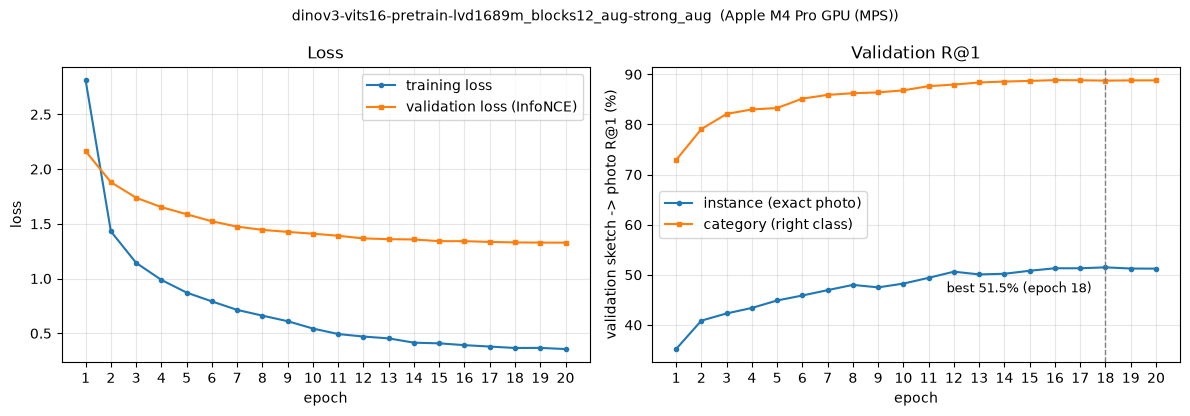

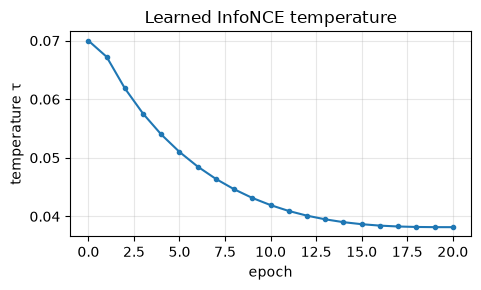

temperature: 0.07 -> 0.0382 (lowest allowed: 0.01)


In [19]:
# Task 4: training curves
epochs = [h['epoch'] for h in history]
best_h = max(history, key=lambda h: h['val_inst_r1'])

fig, (ax_loss, ax_r1) = plt.subplots(1, 2, figsize=(12, 4.2))
ax_loss.plot(epochs, [h['train_loss'] for h in history], 'o-', ms=3, label='training loss')
ax_loss.plot(epochs, [h['val_loss'] for h in history], 's-', ms=3, label='validation loss (InfoNCE)')
ax_loss.set_xlabel('epoch')
ax_loss.set_ylabel('loss')
ax_loss.set_title('Loss')

ax_r1.plot(epochs, [h['val_inst_r1'] for h in history], 'o-', ms=3, label='instance (exact photo)')
ax_r1.plot(epochs, [h['val_cat_r1'] for h in history], 's-', ms=3, label='category (right class)')
ax_r1.axvline(best_h['epoch'], color='grey', ls='--', lw=1)
ax_r1.annotate(f"best {best_h['val_inst_r1']:.1f}% (epoch {best_h['epoch']})",
               (best_h['epoch'], best_h['val_inst_r1']), textcoords='offset points',
               xytext=(-10, -18), ha='right', fontsize=9)
ax_r1.set_xlabel('epoch')
ax_r1.set_ylabel('validation sketch -> photo R@1 (%)')
ax_r1.set_title('Validation R@1')

for ax in (ax_loss, ax_r1):
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_xticks(epochs if len(epochs) <= 20 else epochs[::5])
fig.suptitle(f'{RUN_NAME}  ({HARDWARE})', fontsize=10)
plt.tight_layout()
plt.savefig(RUN_DIR / 'curves.png', dpi=150)
plt.show()

# Extra (for Q2): how the learned temperature moved
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([0] + epochs, [CFG['TEMP_INIT']] + [h['temperature'] for h in history], 'o-', ms=3)
ax.set_xlabel('epoch')
ax.set_ylabel('temperature τ')
ax.set_title('Learned InfoNCE temperature')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_DIR / 'temperature.png', dpi=150)
plt.show()
print(f"temperature: {CFG['TEMP_INIT']} -> {history[-1]['temperature']:.4f} "
      f"(lowest allowed: 0.01)")


# Part E: Evaluate (sections 14–16)

## 14. Test results
Loads your **best** model (the epoch with the highest validation instance R@1) and scores it on the test split, next
to the raw-DINO baseline and the published results. Choose your settings with the validation scores only: the test
set is for the final score.

**For your report:** this table is your main result.

In [20]:
# @title 14. Test results (given) { display-mode: "form" }
load_best()
test_sk, test_ph = embed_split(sketch_model, test_split)
test_results = evaluate(test_sk, test_ph, test_split)
print_results({f'{SLUG} raw (no training)': baseline, RUN_NAME: test_results})

print("\nSketch -> exact photo, R@1 (the Sketchy paper's score):")
print(f"  {'Your model':52s} {test_results['s2p_inst'][1]:6.1f}%")
print(f"  {'Raw DINO, no training':52s} {baseline['s2p_inst'][1]:6.1f}%")
for name, r1 in PUBLISHED_R1.items():
    print(f'  {name:52s} {r1:6g}%')
print("  (Our 1,250 test photos are 10 random photos per class, not the paper's exact list,\n"
      "   so this comparison is close, not exact.)")

results_json = dict(cfg=CFG, hardware=HARDWARE, train_minutes=train_minutes, epochs=len(history),
                    test=test_results)
with open(RUN_DIR / 'results.json', 'w') as f:
    json.dump(results_json, f, indent=1)

                           dinov3-vits16-pretrain-lvd1689  dinov3-vits16-pretrain-lvd1689
                                        R@1    R@5   R@10               R@1    R@5   R@10
Sketch->Photo  instance              14.8   37.4   48.6              35.6   76.4   89.8  
Sketch->Photo  category              39.5   65.8   76.2              88.3   96.0   97.8  
Photo->Sketch  instance              36.8   67.8   78.3              50.2   85.7   94.2  
Photo->Sketch  category              78.6   89.9   92.2              92.9   97.6   98.5  

Sketch -> exact photo, R@1 (the Sketchy paper's score):
  Your model                                             35.6%
  Raw DINO, no training                                  14.8%
  Sketchy paper, best model (Sangkloy et al., 2016)      37.1%
  Humans (Sangkloy et al., 2016)                           54%
  Seddati et al., 2022 (fine-tuned ViT)                 62.25%
  (Our 1,250 test photos are 10 random photos per class, not the paper's exact list,
   

## 15. Task 5: retrieval examples
1. Pick about 5 test **sketches**. Show each one with its **top-5 photos**.
2. Pick about 4 test **photos**. Show each one with its **top-5 sketches**.

Give each result a green border if it is the right class and a red border if not, and mark the **exact match** (the
photo the sketch was drawn from). Save the figures to `RUN_DIR`.

<details><summary><b>What you can use</b> (click to open)</summary>

- `test_sk` (all test sketches) and `test_ph` (all test photos): the normalised embeddings from section 14, so a dot
  product gives the cosine similarity.
- `test_split.sketch_pidx`, `test_split.sketch_cls`, `test_split.photo_cls` and the image paths (section 4).
- `load_rgb(path)` to open an image, and `CLASS_NAMES[c]` for the name of class `c`.

</details>

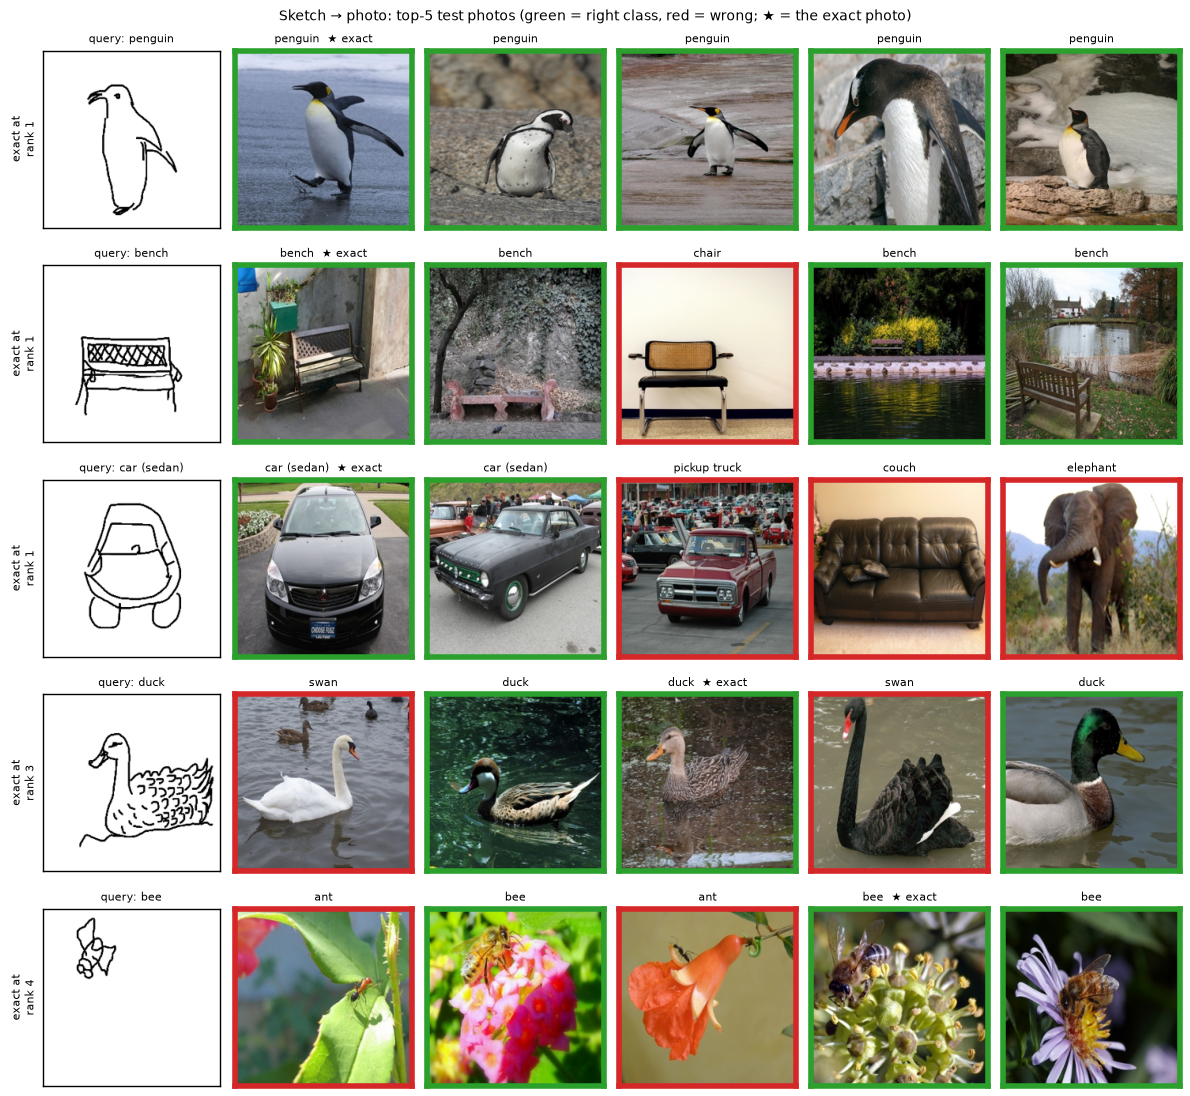

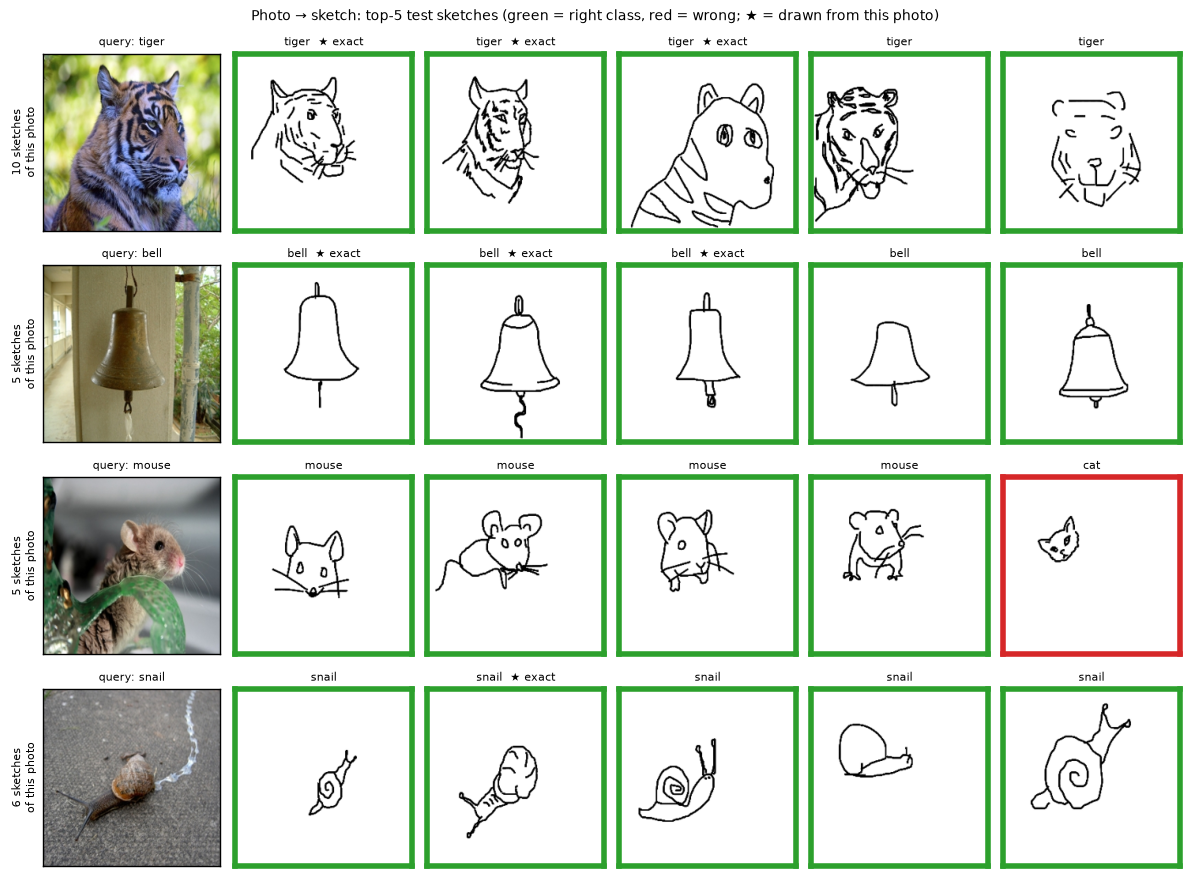

Sketch -> photo queries (row: class, rank of exact photo, top-1 class):
             penguin: exact at rank    1, top-1 = penguin
               bench: exact at rank    1, top-1 = bench
         car (sedan): exact at rank    1, top-1 = car (sedan)
                duck: exact at rank    3, top-1 = swan
                 bee: exact at rank    4, top-1 = ant


In [21]:
# Task 5: retrieval examples in both directions
sim = test_sk.float() @ test_ph.float().T           # [sketches, photos] cosine similarities
s_cls, s_pidx, p_cls = test_split.sketch_cls, test_split.sketch_pidx, test_split.photo_cls

# Rank of the exact photo for every sketch (0 = first)
exact_score = sim[torch.arange(len(sim)), s_pidx]
exact_rank = (sim > exact_score[:, None]).sum(1)
top1_photo = sim.argmax(1)


def pick(candidates, n, rng, used_classes):
    """Up to n candidates from different classes (deterministic, seeded)."""
    candidates = list(candidates)
    rng.shuffle(candidates)
    chosen = []
    for c in candidates:
        cls = int(s_cls[c]) if c < len(s_cls) else None
        if cls in used_classes:
            continue
        chosen.append(c)
        used_classes.add(cls)
        if len(chosen) == n:
            break
    return chosen


def show_image(ax, path, title, color=None, lw=4):
    ax.imshow(load_rgb(path).resize((224, 224)))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color or 'black')
        spine.set_linewidth(lw if color else 1)


GREEN, RED = '#2ca02c', '#d62728'
rng = random.Random(0)
used = set()
successes = pick(torch.nonzero(exact_rank == 0).flatten().tolist(), 3, rng, used)   # exact photo first
wrong_class = torch.nonzero(p_cls[top1_photo] != s_cls).flatten().tolist()
failures = pick(wrong_class, 2, rng, used)                                           # top-1 is the wrong class
s2p_queries = successes + failures

# 1) Sketch -> photo
fig, axes = plt.subplots(len(s2p_queries), 6, figsize=(12, 2.25 * len(s2p_queries)))
for row, j in enumerate(s2p_queries):
    show_image(axes[row, 0], test_split.sketch_paths[j], f'query: {CLASS_NAMES[s_cls[j]]}')
    for k, i in enumerate(sim[j].topk(5).indices.tolist()):
        right_class = int(p_cls[i]) == int(s_cls[j])
        title = CLASS_NAMES[p_cls[i]] + ('  ★ exact' if i == int(s_pidx[j]) else '')
        show_image(axes[row, k + 1], test_split.photo_paths[i], title, GREEN if right_class else RED)
    axes[row, 0].set_ylabel(f'exact at\nrank {int(exact_rank[j]) + 1}', fontsize=8)
fig.suptitle('Sketch → photo: top-5 test photos (green = right class, red = wrong; ★ = the exact photo)',
             fontsize=10)
plt.tight_layout()
plt.savefig(RUN_DIR / 'retrieval_s2p.png', dpi=130)
plt.show()

# 2) Photo -> sketch (only photos that have test sketches)
sim_p2s = sim.T                                       # [photos, sketches]
photos = test_split.photos_with_sketches
own_top1 = [i for i in photos if int(s_pidx[sim_p2s[i].argmax()]) == i]
not_own = [i for i in photos if int(s_pidx[sim_p2s[i].argmax()]) != i]
rng = random.Random(1)
used_p = set()


def pick_photos(cands, n):
    cands = list(cands)
    rng.shuffle(cands)
    out = []
    for i in cands:
        if int(p_cls[i]) not in used_p:
            out.append(i)
            used_p.add(int(p_cls[i]))
        if len(out) == n:
            break
    return out


p2s_queries = pick_photos(own_top1, 2) + pick_photos(not_own, 2)
fig, axes = plt.subplots(len(p2s_queries), 6, figsize=(12, 2.25 * len(p2s_queries)))
for row, i in enumerate(p2s_queries):
    show_image(axes[row, 0], test_split.photo_paths[i], f'query: {CLASS_NAMES[p_cls[i]]}')
    for k, j in enumerate(sim_p2s[i].topk(5).indices.tolist()):
        right_class = int(s_cls[j]) == int(p_cls[i])
        title = CLASS_NAMES[s_cls[j]] + ('  ★ exact' if int(s_pidx[j]) == i else '')
        show_image(axes[row, k + 1], test_split.sketch_paths[j], title, GREEN if right_class else RED)
    n_own = len(test_split.sketches_of[i])
    axes[row, 0].set_ylabel(f'{n_own} sketches\nof this photo', fontsize=8)
fig.suptitle('Photo → sketch: top-5 test sketches (green = right class, red = wrong; ★ = drawn from this photo)',
             fontsize=10)
plt.tight_layout()
plt.savefig(RUN_DIR / 'retrieval_p2s.png', dpi=130)
plt.show()

# Numbers for Q8
print('Sketch -> photo queries (row: class, rank of exact photo, top-1 class):')
for j in s2p_queries:
    print(f'  {CLASS_NAMES[s_cls[j]]:>18s}: exact at rank {int(exact_rank[j]) + 1:4d}, '
          f'top-1 = {CLASS_NAMES[p_cls[top1_photo[j]]]}')


## 16. Task 6: classify sketches from a list of classes
DINO has no text side, so it cannot compare a sketch with the word "frog". Instead, each class is described by a
**class prototype**: one vector that stands for the whole class.
1. **Prototypes:** for each class, L2-normalise the features of its training photos, average them, then L2-normalise
   the average.
2. **Guess:** the guessed class of a test sketch is its most similar prototype.
3. **Accuracy:** the % of **all** test sketches guessed right. Store it in `class_acc`.
4. **Figure:** about 8 test sketches with their guesses (green = right, red = wrong), saved as
   `RUN_DIR / 'class_guesses.png'`.

Then run the check cell.

<details><summary><b>What you can use</b> (click to open)</summary>

- `train_split.photo_feats`, with the classes in `train_split.photo_cls`.
- `test_sk` (from section 14) and `test_split.sketch_cls`.
- This works because your model maps sketches into the same space as the photo features.

</details>

Class-from-list accuracy: 86.3% of 7,548 test sketches (random guessing: 0.8%)
For comparison, category R@1 (nearest test photo's class): 88.3%
Most common mistakes (true -> guessed: count):
  seagull -> penguin: 14
  seagull -> duck: 14
  tiger -> lion: 11
  beetle -> ant: 11
  bear -> teddy bear: 11
  cow -> sheep: 9


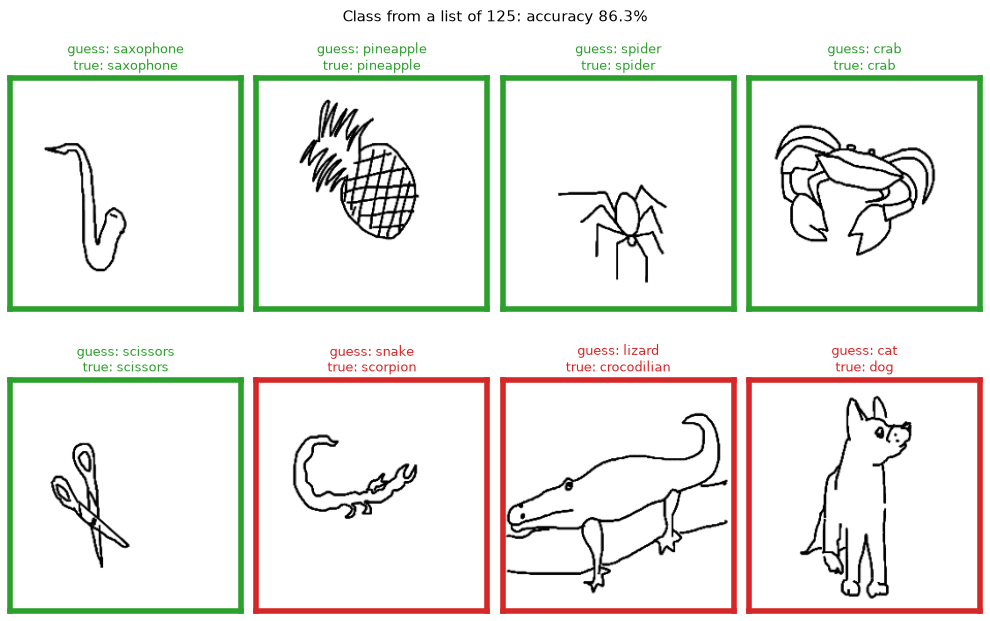

In [22]:
# Task 6: classify each test sketch with class prototypes
# 1. Prototypes: normalise each training photo feature, average per class, normalise again
photo_f = F.normalize(train_split.photo_feats.float().cpu(), dim=-1)
n_classes = len(CLASSES)
protos = torch.zeros(n_classes, photo_f.shape[1]).index_add_(0, train_split.photo_cls, photo_f)
protos = F.normalize(protos, dim=-1)                       # [125, 768]

# 2. Guess: the most similar prototype (test_sk is already normalised)
guess = (test_sk.float().cpu() @ protos.T).argmax(1)
truth = test_split.sketch_cls

# 3. Accuracy over all test sketches
class_acc = (guess == truth).float().mean().item() * 100
print(f'Class-from-list accuracy: {class_acc:.1f}% of {len(truth):,} test sketches '
      f'(random guessing: {100 / n_classes:.1f}%)')
print(f"For comparison, category R@1 (nearest test photo's class): {test_results['s2p_cat'][1]:.1f}%")

# Extra (for Q7): the most common confusions
pairs = {}
for t, g in zip(truth.tolist(), guess.tolist()):
    if t != g:
        pairs[(t, g)] = pairs.get((t, g), 0) + 1
print('Most common mistakes (true -> guessed: count):')
for (t, g), n in sorted(pairs.items(), key=lambda kv: -kv[1])[:6]:
    print(f'  {CLASS_NAMES[t]} -> {CLASS_NAMES[g]}: {n}')

# 4. Figure: 8 test sketches (5 right, 3 wrong when possible), green = right, red = wrong
rng = random.Random(0)
right = [j for j in range(len(truth)) if guess[j] == truth[j]]
wrong = [j for j in range(len(truth)) if guess[j] != truth[j]]
n_wrong = min(3, len(wrong))
shown = rng.sample(right, 8 - n_wrong) + rng.sample(wrong, n_wrong)
fig, axes = plt.subplots(2, 4, figsize=(10, 6.6))
for ax, j in zip(axes.flat, shown):
    ok = guess[j] == truth[j]
    ax.imshow(load_rgb(test_split.sketch_paths[j]).resize((224, 224)))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'guess: {CLASS_NAMES[guess[j]]}\ntrue: {CLASS_NAMES[truth[j]]}', fontsize=9,
                 color='#2ca02c' if ok else '#d62728')
    for spine in ax.spines.values():
        spine.set_edgecolor('#2ca02c' if ok else '#d62728')
        spine.set_linewidth(4)
fig.suptitle(f'Class from a list of {n_classes}: accuracy {class_acc:.1f}%', fontsize=11)
plt.tight_layout(h_pad=2.5)
plt.savefig(RUN_DIR / 'class_guesses.png', dpi=130)
plt.show()


In [23]:
# @title Check Task 6 { display-mode: "form" }
assert class_acc is not None, 'Set class_acc to your accuracy in % (0 to 100).'
assert 0 <= float(class_acc) <= 100, 'Set class_acc to your accuracy in % (0 to 100).'
results_json['class_acc'] = float(class_acc)
with open(RUN_DIR / 'results.json', 'w') as f:
    json.dump(results_json, f, indent=1)
print('Task 6 check passed: class_acc saved to results.json')

Task 6 check passed: class_acc saved to results.json


# Part F: Experiments (section 17, Task 7)

## 17. Compare all your runs (ablation table)
One row per run saved in your runs folder, plus the no-training baseline. `R@1/5/10` = sketch → exact photo;
`vs base` = this run's R@1 minus your base run's (**+** = the change helped). Your base run is your newest full run
with an empty `RUN_TAG` and the default settings. Without `SAVE_TO_DRIVE=True`, runs from earlier Colab sessions are
gone.

<details><summary><b>All the columns</b> (click to open)</summary>

| Column | Meaning |
|---|---|
| `R@1`, `R@5`, `R@10` | sketch → exact photo (instance) |
| `cat R@1` | sketch → a photo of the right class (category) |
| `p2s R@1` | photo → one of its own sketches (instance) |
| `class acc` | your Task 6 accuracy |
| `minutes` | training time |
| `vs base` | this run's `R@1` minus your base run's |

</details>

In [24]:
# @title 17. Compare all your runs (given) { display-mode: "form" }
def load_json(path):
    with open(path) as f:
        return json.load(f)


runs = []   # (folder name, results, time saved)
for f in RUNS.glob('*/results.json'):
    runs.append((f.parent.name, load_json(f), f.stat().st_mtime))
runs.sort(key=lambda r: r[0])
baselines = []
for f in sorted(RUNS.glob('baseline_*.json')):
    baselines.append((f.stem + ' (no training)', load_json(f)))

# The base run: the newest full run with no RUN_TAG and the default settings
BASE_SETTINGS = dict(TRAIN_BLOCKS=12, HIDDEN_DIM=1024, AUG='none', EPOCHS=None, BATCH_SIZE=128,
                     LR_HEAD=1e-3, LR_BACKBONE=2e-5, WEIGHT_DECAY=0.05, WARMUP_STEPS=100,
                     TEMP_INIT=0.07, SEED=0)


def is_full_untagged(cfg):
    return not cfg.get('RUN_TAG') and not cfg.get('QUICK_RUN')


def has_base_settings(cfg):
    if cfg.get('LOSS', 'infonce') != 'infonce':
        return False
    return all(cfg.get(k) == v for k, v in BASE_SETTINGS.items())


full_untagged = [r for r in runs if is_full_untagged(r[1].get('cfg', {}))]
base_runs = [r for r in full_untagged if has_base_settings(r[1]['cfg'])]
base = None
base_r1 = None
if base_runs:
    base = max(base_runs, key=lambda r: r[2])   # the newest
    base_r1 = base[1]['test']['s2p_inst']['1']

width = max([len(r[0]) for r in runs + baselines] + [10])


def show_row(name, t, acc='-', minutes='-', is_base=False):
    """Print one table row."""
    inst = t['s2p_inst']
    if is_base:
        vs = 'base'
    elif base:
        vs = f"{inst['1'] - base_r1:+.1f}"
    else:
        vs = '-'
    print(f"{name:{width}s} {inst['1']:6.1f} {inst['5']:6.1f} {inst['10']:6.1f} "
          f"{t['s2p_cat']['1']:8.1f} {t['p2s_inst']['1']:8.1f} {acc:>9s} {minutes:>7s} {vs:>8s}")


print(f"{'run':{width}s} {'R@1':>6s} {'R@5':>6s} {'R@10':>6s} {'cat R@1':>8s} {'p2s R@1':>8s} "
      f"{'class acc':>9s} {'minutes':>7s} {'vs base':>8s}")
for name, d in baselines:
    show_row(name, d['test'])
for name, d, _ in runs:
    acc = '-'
    if d.get('class_acc') is not None:
        acc = f"{d['class_acc']:.1f}"
    is_base = base is not None and name == base[0]
    show_row(name, d['test'], acc, f"{d['train_minutes']:.1f}", is_base)

if base:
    print(f'\nBase run: {base[0]}')
else:
    print("\nNo base run yet (a full run with RUN_TAG = '' and the default settings), "
          "so 'vs base' is empty.")
base_names = {r[0] for r in base_runs}
for name, *_ in full_untagged:
    if name not in base_names:
        print(f'WARNING: {name} has no RUN_TAG but does not use the default settings, '
              'so it is not used as the base run. Give each modification its own RUN_TAG.')

run                                                        R@1    R@5   R@10  cat R@1  p2s R@1 class acc minutes  vs base
baseline_dinov3-vits16-pretrain-lvd1689m (no training)    14.8   37.4   48.6     39.5     36.8         -       -    -25.4
dinov3-vits16-pretrain-lvd1689m_blocks12_aug-none         40.2   79.2   90.6     88.0     56.8      86.4    53.3     base
dinov3-vits16-pretrain-lvd1689m_blocks12_aug-strong_aug   35.6   76.4   89.8     88.3     50.2      86.3    51.8     -4.6

Base run: dinov3-vits16-pretrain-lvd1689m_blocks12_aug-none


## Task 7: two modifications, alone and together (ablation study)
Pick two modifications, **A** and **B** (ideas: handout §2.6). Train three runs, each with its own `RUN_TAG`:
**A only**, **B only**, and **A + B** (about 75 minutes on a T4). Then use the section 17 table to say which change
helped, which hurt, and whether A + B beat each one alone.

**To make a run:** change the settings in section 1 (or your code), set a new `RUN_TAG`, and **Run all**. If a
modification needs new code, add a setting to `CFG` (e.g. `LOSS='triplet'`) and an `if` in your code, so you can
switch between versions without deleting anything.

**Watch out:** `TRAIN_BLOCKS = 0` trains for 60 epochs by default and turns `AUG` off, so don't pair it with sketch
augmentation.

**Optional:** re-run your base with `SEED=1` and `RUN_TAG='seed1'` to see how much scores move by chance (Q9).

<details><summary><b>More about the ideas</b> (click to open)</summary>

- **The Sketchy paper's loss:** a triplet loss (the sketch must be closer to its own photo than to a wrong photo, by a
  margin) plus a classification loss (predict each sketch's class). In the paper, the triplet loss alone reached
  22.8%, and adding the classification loss raised it to 37.1%. Do you see the same effect?
- **Hadsell et al.'s contrastive loss:** pull matching pairs together, and push non-matching pairs at least a margin
  apart.
- **Harder negatives:** batches with several photos of the same class, so the model must tell similar photos apart.
- **Not in the handout:** a trainable head on the photo side too; the bigger DINOv3 model
  (`facebook/dinov3-vitb16-pretrain-lvd1689m`, e.g. with `TRAIN_BLOCKS = 4`); a bigger or smaller head
  (`HIDDEN_DIM`); test-time flip (average the embeddings of a sketch and its mirror image).

</details>

## Before you submit
- [ ] Your base run used `QUICK_RUN=False`, and every check cell passed.
- [ ] Right after the base run, you downloaded this notebook with its outputs as `base_run.ipynb`.
- [ ] You ran A only, B only and A + B (Task 7), and the section 17 table shows them with your base run.
- [ ] You downloaded the notebook with all your code (including Task 7) as `final.ipynb`.
- [ ] You typed your base run's folder name into `BASE_RUN` below and ran the cell (it zips your run folders).
- [ ] Your report answers Q1–Q10 (handout §2.7).
- [ ] One zip named `<studentID>.zip` (or `<id1>_<id2>.zip`) with both notebooks, the runs zip and the report PDF.

In [25]:
# @title Download your run folders as one zip { display-mode: "form" }
BASE_RUN = 'dinov3-vits16-pretrain-lvd1689m_blocks12_aug-none'  # @param {type:"string"}
# BASE_RUN: your base run's folder name (printed in section 17). Its best.pt is the only weights file included.
if IN_COLAB:
    out = Path('/content/runs_for_submission.zip')
else:
    out = RUNS.parent / 'runs_for_submission.zip'
with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(RUNS.rglob('*')):
        if f.is_dir():
            continue
        if f.suffix == '.pt' and f.parent.name != BASE_RUN:   # weights: base run only
            continue
        z.write(f, Path('runs') / f.relative_to(RUNS))
print(f'Wrote {out} ({out.stat().st_size / 1e6:.1f} MB)')
if not BASE_RUN:
    print('Note: BASE_RUN is empty, so no weights were included. '
          'Type your base run folder name and run this cell again.')
elif not (RUNS / BASE_RUN / 'best.pt').exists():
    missing_file = RUNS / BASE_RUN / 'best.pt'
    print(f'WARNING: {missing_file} was not found. Check the folder name in section 17.')
if IN_COLAB:
    from google.colab import files
    files.download(str(out))

Wrote runs_for_submission.zip (50.6 MB)
